# I. Impact environnemental de l’alimentation
- Comparer les impacts environnementaux des grands groupes d’aliments
- Statistiques descriptives + visualisation
- Comparer en particulier les produits animaux et végétaux
- Identifier les principaux postes responsables de l’impact climatique : agriculture, transformation, emballage, transport...

# II. Les alternatives végétales : vraiment meilleures ?
- Identifier les principales catégories d’alternatives végétales
- Comparer leurs impacts environnementaux avec ceux des produits animaux qu’elles peuvent remplacer
- Comparer leur profil nutritionnel et étudier colonne SAIN et LIM
- Voir si certaines alternatives végétales présentent effectivement un compromis entre impact environnemental et qualité nutritionnelle
# III. Santé et environnement : existe-t-il un double gain ?
- Chercher les aliments qui combinent faible impact environnemental et bonne qualité nutritionnelle
- Comparer notamment les profils des aliments animaux, végétaux et alternatives végétales
- Conclure sur l’existence ou non d’un arbitrage santé–environnement, et sur les aliments qui semblent permettre un double gain

In [2]:
# Chargement de la base de données fusionnée
import pandas as pd
database = pd.read_csv("database.csv")

print("Dimensions de la base :", database.shape)
database.head(5)

Dimensions de la base : (2296, 34)


,code_agb,code_ciqual,groupe_aliment,sous_groupe_aliment,nom_produit,nom_lci,preparation,dqr,score_unique_ef,changement_climatique,...,Lipides (g 100 g),Sucres (g 100 g),Fibres alimentaires (g 100 g),Sel chlorure de sodium (g 100 g),Calcium (mg 100 g),Fer (mg 100 g),Sodium (mg 100 g),Vitamine C (mg 100 g),SAIN,LIM
0,11172,11172,aides culinaires et ingrédients divers,aides culinaires,"Court-bouillon pour poissons, déshydraté","Aromatic stock cube, for fish, dehydrated",Pas de préparation,2.24,1.870,7.58,...,23.00,4.50,2.50,47.500,0.0,0.00,19000.0,0.0,1.370826,100.000000
1,25525,25525,aides culinaires et ingrédients divers,aides culinaires,"Pizza, sauce garniture pour",Topping sauce for pizza,Pas de préparation,2.19,0.148,0.94,...,0.75,4.57,2.81,0.960,50.0,0.90,385.0,7.0,16.109676,7.258677
2,11214,11214,aides culinaires et ingrédients divers,aides culinaires,"Préparation culinaire à base de soja, type ""cr...","Soy ""cream"" preparation",Pas de préparation,1.75,0.148,1.17,...,14.70,1.60,0.00,0.063,16.0,0.47,25.0,0.0,1.404142,3.830630
3,11084,11084,aides culinaires et ingrédients divers,algues,"Agar (algue), cru","Seaweed, agar, raw",Pas de préparation,2.77,1.550,11.80,...,0.03,0.28,0.50,0.023,54.0,1.86,9.0,0.0,16.397663,0.290785
4,20995,20995,aides culinaires et ingrédients divers,algues,"Ao-nori (Enteromorpha sp.), séchée ou déshydratée","Sea lettuce (Enteromorpha sp.), dried or dehyd...",Pas de préparation,2.77,1.550,11.80,...,2.50,1.35,35.10,10.200,1550.0,205.00,4090.0,48.8,100.000000,44.917791


I. Impact environnemental de l'alimentation

I.1. Comparaison des impacts environnementaux des grands groupes alimentaires

In [3]:
# Nombre de groupes et de sous-groupes alimentaires
print("Nombre de groupes alimentaires :", database["groupe_aliment"].nunique())
print("Nombre de sous-groupes alimentaires :", database["sous_groupe_aliment"].nunique())

# Nombre de sous-groupes et de produits par groupe alimentaire
composition_groupes = database.groupby("groupe_aliment").agg(
    nombre_sous_groupes=("sous_groupe_aliment", "nunique"),
    nombre_produits=("nom_produit", "count")
)

# Affichage du tableau
display(composition_groupes.sort_values("nombre_produits", ascending=False))

Nombre de groupes alimentaires : 11
Nombre de sous-groupes alimentaires : 60


,nombre_sous_groupes,nombre_produits
groupe_aliment,,
"viandes, œufs, poissons",12,637
"fruits, légumes, légumineuses et oléagineux",5,391
produits céréaliers,5,333
entrées et plats composés,7,300
lait et produits laitiers,4,196
aides culinaires et ingrédients divers,9,156
boissons,3,134
produits sucrés,4,48
aliments infantiles,4,38


In [4]:
# Comparaison des impacts environnementaux des grands groupes d’aliments

# Liste des indicateurs environnementaux disponibles dans la base fusionnée
indicateurs = [
    "score_unique_ef",
    "changement_climatique",
    "utilisation_du_sol",
    "epuisement_ressources_eau",
    "particules_fines",
    "toxicite_humaine_non_cancerogenes",
    "toxicite_humaine_cancerogenes"
]

# Calcul des statistiques environnementales par groupe alimentaire
stats_groupes = database.groupby("groupe_aliment").agg(
    nombre_produits=("nom_produit", "count"),
    **{
        indicateur + "_moyenne": (indicateur, "mean")
        for indicateur in indicateurs
    },
    **{
        indicateur + "_mediane": (indicateur, "median")
        for indicateur in indicateurs
    }
)

# Affichage des résultats
display(stats_groupes)

,nombre_produits,score_unique_ef_moyenne,changement_climatique_moyenne,utilisation_du_sol_moyenne,epuisement_ressources_eau_moyenne,particules_fines_moyenne,toxicite_humaine_non_cancerogenes_moyenne,toxicite_humaine_cancerogenes_moyenne,score_unique_ef_mediane,changement_climatique_mediane,utilisation_du_sol_mediane,epuisement_ressources_eau_mediane,particules_fines_mediane,toxicite_humaine_non_cancerogenes_mediane,toxicite_humaine_cancerogenes_mediane
groupe_aliment,,,,,,,,,,,,,,,
aides culinaires et ingrédients divers,156,0.491599,3.806494,170.781154,4.013111,3.115596e-07,6.355372e-08,2.152250e-09,0.2990,2.3650,83.85,2.4750,1.760000e-07,4.465000e-08,1.215000e-09
aliments infantiles,38,0.200318,1.749921,74.329211,1.052105,1.437737e-07,2.420789e-08,1.844553e-09,0.1440,1.2100,50.50,0.9420,7.325000e-08,1.895000e-08,6.510000e-10
boissons,134,0.143213,1.237856,45.530680,1.350146,7.808706e-08,3.619228e-08,1.080540e-09,0.1170,0.8345,19.05,0.3670,5.550000e-08,1.185000e-08,4.705000e-10
entrées et plats composés,300,0.595310,4.770027,236.383667,3.492481,4.998105e-07,7.362200e-08,2.925997e-09,0.4230,3.2700,136.00,1.1700,2.790000e-07,4.815000e-08,2.225000e-09
"fruits, légumes, légumineuses et oléagineux",391,0.219991,1.478141,135.115217,3.671992,1.063481e-07,4.673046e-08,1.869307e-09,0.1360,1.0400,33.20,0.6820,6.050000e-08,2.300000e-08,8.380000e-10
glaces et sorbets,25,0.259720,2.094400,74.880000,1.196920,1.545760e-07,2.548400e-08,1.061880e-09,0.2380,1.9800,67.70,0.6660,1.600000e-07,2.500000e-08,1.060000e-09
lait et produits laitiers,196,0.476781,4.472602,230.414796,1.024429,4.404061e-07,5.433265e-08,2.231036e-09,0.5005,5.1900,239.00,0.6920,4.270000e-07,6.090000e-08,2.450000e-09
matières grasses,38,0.572816,4.957105,345.928947,7.515579,3.867368e-07,9.436316e-08,4.504658e-09,0.4435,3.6250,339.50,0.8625,2.905000e-07,6.370000e-08,3.320000e-09
produits céréaliers,333,0.298500,2.617913,143.727027,2.533186,1.776829e-07,7.203012e-08,1.656595e-09,0.2840,2.2400,134.00,1.0100,1.700000e-07,3.000000e-08,1.550000e-09


In [5]:
# Recherche des groupes ayant les impacts les plus élevés

for indicateur in indicateurs:
    print(indicateur)
    print("Moyenne maximale :", stats_groupes[indicateur + "_moyenne"].idxmax())
    print("Médiane maximale :", stats_groupes[indicateur + "_mediane"].idxmax())

score_unique_ef
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
changement_climatique
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
utilisation_du_sol
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : matières grasses
epuisement_ressources_eau
Moyenne maximale : matières grasses
Médiane maximale : aides culinaires et ingrédients divers
particules_fines
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
toxicite_humaine_non_cancerogenes
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
toxicite_humaine_cancerogenes
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons


Le groupe viandes, œufs et poissons présente la moyenne et la médiane les plus élevées pour 5 indicateurs sur 7. Les résultats diffèrent pour l'utilisation des sols : les viandes, œufs et poissons ont la moyenne la plus élevée, mais les matières grasses ont la médiane la plus élevée. L'épuisement des ressources en eau présente un résultat différent : les matières grasses ont la moyenne la plus élevée, tandis que les aides culinaires et ingrédients divers ont la médiane la plus élevée.

In [ ]:
# Recherche des groupes ayant les impacts les plus faibles

for indicateur in indicateurs:
    print(indicateur)
    print("Moyenne minimale :", stats_groupes[indicateur + "_moyenne"].idxmin())
    print("Médiane minimale :", stats_groupes[indicateur + "_mediane"].idxmin())

Les boissons ont globalement les impacts environnementaux les plus faibles parmi les 11 groupes alimentaires.

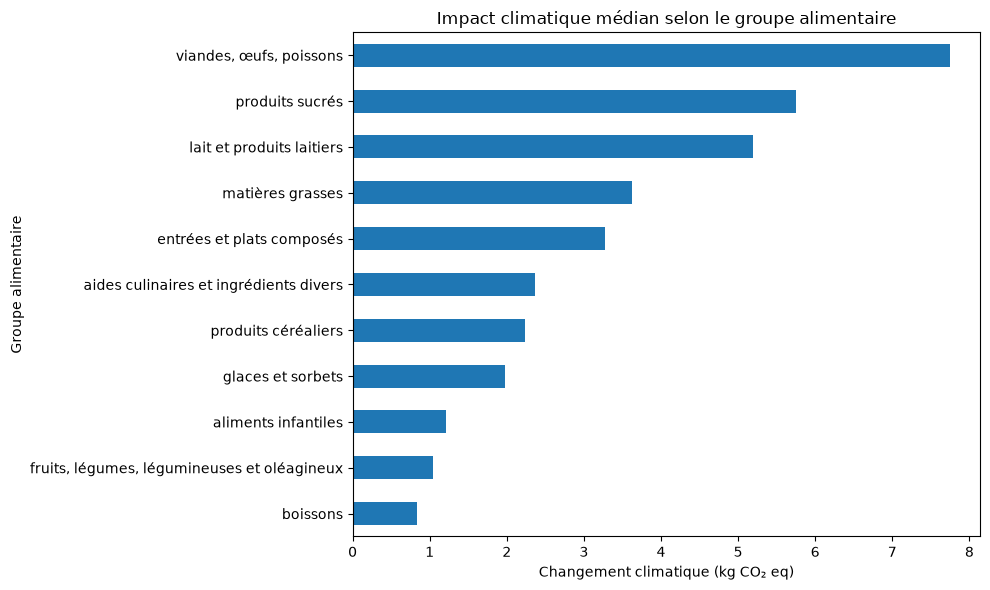

In [7]:
# Graphique sur l'impact climatique médian des groupes alimentaires

import matplotlib.pyplot as plt

impact_climatique_groupes = (
    database.groupby("groupe_aliment")["changement_climatique"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 6))

impact_climatique_groupes.plot(kind="barh")

plt.xlabel("Changement climatique (kg CO₂ eq)")
plt.ylabel("Groupe alimentaire")
plt.title("Impact climatique médian selon le groupe alimentaire")

plt.tight_layout()
plt.show()

Ce graphique montre que le groupe « viandes, œufs, poissons » présente l'impact climatique médian le plus élevé parmi les groupes alimentaires étudiés. 

I.2. Identification des principaux postes responsables de l’impact climatique

In [6]:
# Identification des principaux postes du cycle de vie responsables de l’impact climatique

postes_climatiques = [
    "changement_climatique_agriculture",
    "changement_climatique_transformation",
    "changement_climatique_emballage",
    "changement_climatique_transport",
    "changement_climatique_distribution",
    "changement_climatique_consommation"
]

# Calcul de la moyenne et de la médiane pour chaque poste
stats_postes = database[postes_climatiques].agg(["mean", "median"]).T

# Renommage des colonnes
stats_postes.columns = ["moyenne", "mediane"]

# Classement des postes selon leur impact moyen 
stats_postes = stats_postes.sort_values(
    "moyenne", ascending=False
)

# Affichage du tableau final
display(stats_postes)

,moyenne,mediane
changement_climatique_agriculture,4.731860,1.65000
changement_climatique_emballage,0.456006,0.40100
changement_climatique_transport,0.388006,0.28350
changement_climatique_transformation,0.250495,0.17050
changement_climatique_consommation,0.045827,0.00683
changement_climatique_distribution,0.036326,0.03680


Les résultats montrent que l'agriculture constitue le principal contributeur à l'impact climatique des produits alimentaires étudiés, avec un impact moyen d'environ 4,73 kg CO₂ eq par kg de produit. 

In [ ]:
# Identification des principaux postes du cycle de vie responsables de l’impact climatique par groupe alimentaire

# Calcul de la moyenne pour chaque poste et chaque groupe
moyennes_postes_groupes = database.groupby("groupe_aliment")[postes_climatiques].mean()

# Affichage des résultats
display(moyennes_postes_groupes)

L'agriculture est le principal poste contributeur dans les 11 groupes alimentaires. 

I.3. Hétérogénéité des impacts au sein du groupe « viandes, œufs et poissons »

In [ ]:
# Sélection du groupe viandes, œufs et poissons
animaux = database[
    database["groupe_aliment"] == "viandes, œufs, poissons"
]

# Calcul des statistiques descriptives par sous-groupe
stats_sous_groupes = animaux.groupby("sous_groupe_aliment").agg(
    nombre_produits=("nom_produit", "count"),
    **{
        indicateur + "_moyenne": (indicateur, "mean")
        for indicateur in indicateurs
    },
    **{
        indicateur + "_mediane": (indicateur, "median")
        for indicateur in indicateurs
    }
)

# Affichage du tableau
display(stats_sous_groupes)

In [ ]:
# Recherche des sous-groupes ayant les impacts les plus élevés
for indicateur in indicateurs:
    print("\n", indicateur)
    print("Moyenne maximale :", stats_sous_groupes[indicateur + "_moyenne"].idxmax())
    print("Médiane maximale :", stats_sous_groupes[indicateur + "_mediane"].idxmax())

On constate que les viandes cuites présentent les médianes les plus élevées pour les sept indicateurs environnementaux étudiés.

In [ ]:
# Recherche des sous-groupes ayant les impacts les plus faibles
for indicateur in indicateurs:
    print("\n", indicateur)
    print("Moyenne minimale :", stats_sous_groupes[indicateur + "_moyenne"].idxmin())
    print("Médiane minimale :", stats_sous_groupes[indicateur + "_mediane"].idxmin())

Les substituts de viande présentent globalement les impacts les plus faibles parmi les sous-groupes étudiés.

Si l'on se concentre sur l’impact climatique et le score unique EF global, on constate que les impacts environnementaux sont très hétérogènes au sein du groupe viandes, œufs et poissons. 
Les viandes cuites et crues présentent les impacts climatiques médians les plus élevés, tandis que les œufs et surtout les substituts de viande et de charcuterie présentent des impacts nettement plus faibles. 
Par exemple, la médiane de l'impact climatique des viandes cuites est de 29,70 kg CO₂ eq/kg de produit, contre 2,02 kg CO₂ eq/kg pour les substituts de viande. De plus, les viandes cuites présentent un score unique EF médian de 2,82, contre 0,244 pour les substituts de viande. Ce score est un indicateur synthétique qui regroupe plusieurs impacts environnementaux en un seul indicateur. 
Cependant, ces sous-groupes sont représentés par des effectifs très différents dans la base : les viandes cuites comptent 104 produits et les viandes crues 132, contre 3 produits pour les substituts de charcuterie et 8 pour les substituts de viande. 

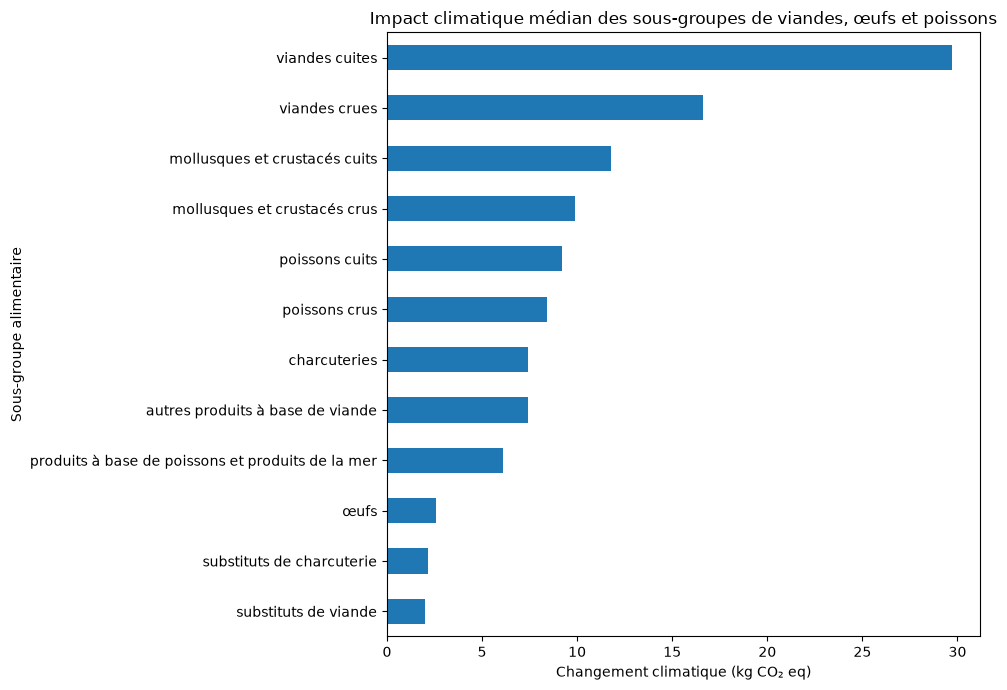

In [8]:
# Graphique sur l'impact climatique médian des sous-groupes
# du groupe "viandes, œufs et poissons"

impact_climatique_sous_groupes = (
    database[
        database["groupe_aliment"] == "viandes, œufs, poissons"
    ]
    .groupby("sous_groupe_aliment")["changement_climatique"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 7))

impact_climatique_sous_groupes.plot(kind="barh")

plt.xlabel("Changement climatique (kg CO₂ eq)")
plt.ylabel("Sous-groupe alimentaire")
plt.title(
    "Impact climatique médian des sous-groupes "
    "de viandes, œufs et poissons"
)

plt.tight_layout()
plt.show()

## III. Santé et environnement : existe-t-il un double gain ?

Dans cette dernière partie, nous essayons de croiser la performance nutritionnelle (scores SAIN et LIM) et l'impact environnemental afin de répondre à trois questions :
1. Existe-t-il un arbitrage systématique entre qualité nutritionnelle et faible impact écologique ?
2. Comment se positionnent les *produits animaux*, les produits adapté à un *régime végétarien* et les *alternatives végétales pures* dans cet espace ?
3. Quels aliments atteignent réellement un *double gain* (frontière d'efficacité) ?

Ce graphique permet de visualiser les impacts climatiques médians des différents sous-groupes. Il met en évidence l'impact élevé des viandes cuites.

In [ ]:
import re
import pandas as pd

# Définition du ratio SAIN/LIM
df1 = pd.read_csv("database.csv")
df1["ratio_sain_lim"] = df1["SAIN"] / df1["LIM"]

# Définition des groupes d'analyse
def classificateur(row):
  groupe = str(row["groupe_aliment"]).lower()
  sous_grp = str(row["sous_groupe_aliment"]).lower()
  nom = str(row["nom_produit"]).lower()

  # Exceptions 100 % végétales (pour parer à certains faux amis linguistiques à partir de lait de coco)
  exceptions_veganes = [
      "soja","tofu","seitan",
      "végétale","végétal",
      "convient aux véganes",
      "lait de coco","crème de coco",
      "beurre de cacahuète","haricot beurre",
      "melon miel",
  ]
  if any(mot in nom for mot in exceptions_veganes) and "poulet" not in nom:
    if "ne convient pas aux véganes" in nom or "fromage" in nom:
      return "vege_non_vegan"
    return "vegan"

  # Produits animaux (viandes, poissons, fruits de mer, charcuteries, plats carnés)
  if groupe == "viandes, œufs, poissons" and sous_grp != "œufs":
    return "animal"
  if sous_grp in ["autres matières grasses", "huiles de poissons"]:
    return "animal"

  mots_animaux = (
      r"\b(viande|boeuf|bœuf|veau|porc|jambon|lardons?|poulet|volaille|dinde|canard|"
      r"agneau|mouton|lapin|tripes|escargots?|saucisses?|saucissons?|merguez|chorizo|"
      r"salami|speck|pâté|bolognaise|carbonara|lorraine|kebab|hot-dog|hamburger|"
      r"cheeseburger|croque-monsieur|croque-madame|cassoulet|chili con carne|"
      r"choucroute garnie|pot-au-feu|osso buco|coq au vin|moussaka|paëlla|tajine|"
      r"poissons?|saumon|thon|anchois|crevettes?|crabe|moules?|st jacques|"
      r"saint-jacques|fruits de mer|produits de la mer|sushi|maki|gélatine)\b"
  )
  if (re.search(mots_animaux, nom)
      and "sans viande" not in nom
      and "végétal" not in nom
  ):
    return "animal"

  # 2. Produits végétariens non végans (œufs, lait, fromage, beurre, pâtisseries)
  if groupe == "lait et produits laitiers" or sous_grp in [
      "œufs","beurres","glaces",
      "desserts glacés","gâteaux et pâtisseries",
  ]:
    return "vege_non_vegan"

  mots_vege_non_vegan = (
      r"\b(fromages?|roquefort|maroilles|chèvre|tomme|raclette|tartiflette|savoyarde|"
      r"aligot|béchamel|crème|beurre|lait|lactée?s?|yaourt|oeufs?|œufs?|miel|"
      r"mayonnaise|hollandaise|béarnaise|tartare|rouille|brioche|croissant|quiche|"
      r"gratin|lasagnes|canelloni|raviolis?|ravioles|risotto|pizza aux légumes)\b"
  )
  if re.search(mots_vege_non_vegan, nom):
    return "vege_non_vegan"

  # 3. Produits végans
  return "vegan"


df1["type_base"] = df1.apply(classificateur, axis=1)
df1["est_animal"] = df1["type_base"] == "animal"
df1["est_vegetarien"] = df1["type_base"].isin(["vege_non_vegan", "vegan"])
df1["est_vegan"] = df1["type_base"] == "vegan"


## Vérification: 

print(df1["type_base"].value_counts())
print("\nVérification des dummies :")
print("Animaux     :", df1["est_animal"].sum())
print("Végétariens :", df1["est_vegetarien"].sum())
print("Végans      :", df1["est_vegan"].sum())
print("Total (Animaux + Végétariens) :", (df1["est_animal"] | df1["est_vegetarien"]).sum())

pd.crosstab(df1["groupe_aliment"], df1["type_base"])

type_base
vegan             1047
animal             779
vege_non_vegan     470
Name: count, dtype: int64

Vérification des booléens :
Animaux     : 779
Végétariens : 1517
Végans      : 1047
Total (Animaux + Végétariens) : 2296


type_base,animal,vegan,vege_non_vegan
groupe_aliment,,,
aides culinaires et ingrédients divers,7,125,24
aliments infantiles,4,12,22
boissons,0,126,8
entrées et plats composés,147,105,48
"fruits, légumes, légumineuses et oléagineux",1,384,6
glaces et sorbets,0,3,22
lait et produits laitiers,0,3,193
matières grasses,10,18,10
produits céréaliers,3,224,106


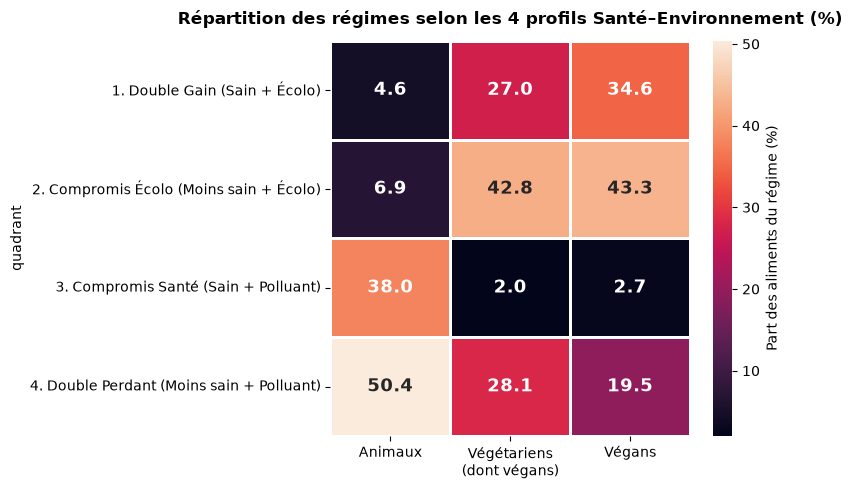

In [ ]:
## Visualisation graphique: découpage de l'espace en 4 cadrans

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

seuil_ef = df1["score_unique_ef"].median()
bon_nutri = (df1["SAIN"] >= 5.0) & (df1["LIM"] < 7.5)
faible_ef = df1["score_unique_ef"] <= seuil_ef

conditions = [
    bon_nutri & faible_ef,
    ~bon_nutri & faible_ef,
    bon_nutri & ~faible_ef,
    ~bon_nutri & ~faible_ef,
    ]

# Puis on classe chaque aliment dans l'un de ces quadrans
labels_q = [
    "1. Double Gain (Sain + Écolo)",
    "2. Compromis Écolo (Moins sain + Écolo)",
    "3. Compromis Santé (Sain + Polluant)",
    "4. Double Perdant (Moins sain + Polluant)",
]
df1["quadrant"] = np.select(conditions, labels_q, default="Autre")

ensembles = {
    "Animaux": df1[df1["est_animal"]],
    "Végétariens\n(dont végans)": df1[df1["est_vegetarien"]],
    "Végans": df1[df1["est_vegan"]],
}

tab_quadrants = pd.DataFrame({
    nom: (sub["quadrant"].value_counts(normalize=True) * 100).round(1)
    for nom, sub in ensembles.items()
}).reindex(labels_q)


fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    tab_quadrants,annot=True,fmt=".1f",
    cbar_kws={"label": "Part des aliments du régime (%)"},
    linewidths=2,linecolor="white",
    annot_kws={"size": 13, "weight": "bold"},
    ax=ax,
)

ax.set_title(
    "Répartition des régimes selon les 4 profils Santé–Environnement (%)",
    fontweight="bold",
    pad=12,
)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Interprétation:

La matrice montre que les produits animaux se concentrent majoritairement dans la zone des Doubles Perdants ou de Compromis Santé, là où le Double Gain reste marginal pour ce type d'aliments. À l'inverse, le passage aux produits végétariens et végans multiplie par plus de six la part d'aliments atteignant le Double Gain (respectivement 27 et 34,6%). 

Toutefois, ici l'analyse manque de finesse car on ne s'est pas restreint aux alternatives à la viande (les produits végans incluant par exemple l'ensemble des fruits et légumes qui sont plus sains mais qui n'offrent pas les mêmes apports nutritifs que la viande / poisson). Ainsi dans un deuxième temps de l'analyse, on restreindra nos observations aux ingrédients "protéinés". 

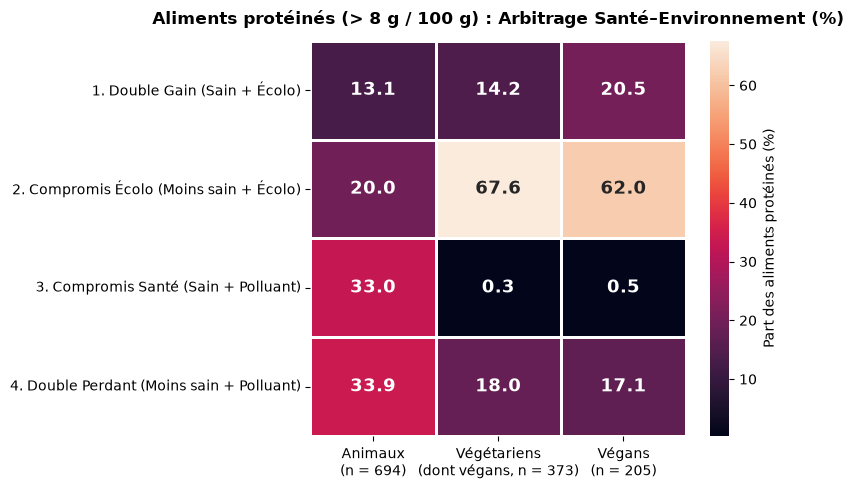

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

col_prot = "Protéines, N x facteur de Jones (g 100 g)"

# 1. Filtrer uniquement les aliments riches en protéines (>= 8 g / 100 g) et qui ne sont pas des épices ou condiments
df_prot = df1[
    (df1[col_prot] >= 8.0)
    & (~df1["groupe_aliment"].isin(["boissons", "aliments infantiles"]))
    & (~df1["sous_groupe_aliment"].isin(["sels", "herbes", "épices", "ingrédients divers", "algues"]))
    & (df1["score_unique_ef"] > 0)
    & (df1["ratio_sain_lim"] > 0)
].copy()

# Ramener l'impact environnemental à 100 g de protéines
df_prot["ef_par_100g_prot"] = (df_prot["score_unique_ef"] / df_prot[col_prot]
) * 100

# 2. Découpage en 4 quadrants à apport protéique équivalent
seuil_ef_prot = df_prot["ef_par_100g_prot"].median()
bon_nutri = (df_prot["SAIN"] >= 5.0) & (df_prot["LIM"] < 7.5)
faible_ef_prot = df_prot["ef_par_100g_prot"] <= seuil_ef_prot

conditions = [
    bon_nutri & faible_ef_prot,
    ~bon_nutri & faible_ef_prot,
    bon_nutri & ~faible_ef_prot,
    ~bon_nutri & ~faible_ef_prot,
]
labels_q = [
    "1. Double Gain (Sain + Écolo)",
    "2. Compromis Écolo (Moins sain + Écolo)",
    "3. Compromis Santé (Sain + Polluant)",
    "4. Double Perdant (Moins sain + Polluant)",
]
df_prot["quadrant"] = np.select(conditions, labels_q, default="Autre")

ensembles = {
    f"Animaux\n(n = {df_prot['est_animal'].sum()})": df_prot[
        df_prot["est_animal"]
    ],
    f"Végétariens\n(dont végans, n = {df_prot['est_vegetarien'].sum()})": (
        df_prot[df_prot["est_vegetarien"]]
    ),
    f"Végans\n(n = {df_prot['est_vegan'].sum()})": df_prot[
        df_prot["est_vegan"]
    ],
}

tab_q_prot = pd.DataFrame({
    nom: (sub["quadrant"].value_counts(normalize=True) * 100).round(1)
    for nom, sub in ensembles.items()
}).reindex(labels_q)

# Heatmap des produits protéinés
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(
    tab_q_prot,
    annot=True,
    fmt=".1f",cbar_kws={"label": "Part des aliments protéinés (%)"},
    linewidths=2,linecolor="white",
    annot_kws={"size": 13, "weight": "bold"},
    ax=ax,
)

ax.set_title(
    "Aliments protéinés (> 8 g / 100 g) : Arbitrage Santé–Environnement (%)",
    fontweight="bold",
    pad=12,
)
ax.set_ylabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Interprétation:

Lorsqu'on restreint l'analyse aux aliments sources de protéines (>8g/100g) et qu'on ramène l'impact environnemental à 100g de protéines, les protéines véganes restent en tête sur le Double Gain (20,5%) contre 13,1% pour les protéines animales, mais un arbitrage majeur apparaît chez les protéines végétales. En effet, une grande partie des produits végétaux protéinés (comme le pain non-complet, les similis carnés salés, ou fromages) ont une empreinte carbone faible par gramme de protéines mais sont pénalisés sur le plan nutritionnel par le sel, les sucres ou les graisses saturées qu'ils contiennent.

In [23]:

# Enfin on s'intéresse au Top 15 des grands vainqueurs protéinés
vainqueurs_prot = df_prot[bon_nutri & faible_ef_prot].copy()
vainqueurs_prot["score_double_gain"] = (vainqueurs_prot["ratio_sain_lim"] / vainqueurs_prot["ef_par_100g_prot"])

print("Répartition des produits protéinés en Double Gain par famille :")
print(vainqueurs_prot["sous_groupe_aliment"].value_counts().head(8))

display(vainqueurs_prot.sort_values("score_double_gain", ascending=False)[
        ["nom_produit","sous_groupe_aliment","type_base",col_prot,"ef_par_100g_prot","ratio_sain_lim",]]
    .head(15)
    .round(1))

Répartition des produits protéinés en Double Gain par famille :
sous_groupe_aliment
viandes crues             33
viandes cuites            24
légumineuses              22
poissons crus             22
pâtes, riz et céréales     8
œufs                       7
substituts de viande       6
poissons cuits             4
Name: count, dtype: int64


,nom_produit,sous_groupe_aliment,type_base,"Protéines, N x facteur de Jones (g 100 g)",ef_par_100g_prot,ratio_sain_lim
948,"Haricot blanc, sec",légumineuses,vegan,23.4,0.4,26.5
1824,"Moule de Méditerranée, crue",mollusques et crustacés crus,animal,10.7,4.5,327.3
955,"Haricot mungo, sec",légumineuses,vegan,25.2,0.4,19.2
963,"Lentille verte, cuite",légumineuses,vegan,10.1,0.9,34.9
1564,"Frik (blé dur immature concassé), cru","pâtes, riz et céréales",vegan,9.6,2.2,85.6
961,"Lentille corail, cuite",légumineuses,vegan,10.6,0.8,30.9
733,"Luzerne, graine",fruits à coque et graines oléagineuses,vegan,29.7,2.8,102.5
953,"Haricot flageolet, vert, sec",légumineuses,vegan,19.1,0.5,18.8
966,"Lentille, germée",légumineuses,vegan,9.0,1.7,55.3
957,"Haricot rouge, cuit",légumineuses,vegan,9.6,0.7,20.9
